# Pilot quickstart: Qwen3-4B calibration

Run the course pilot on 20 validation questions from each dataset, then analyze and package its results. Six context budgets and three distractor seeds produce 640 evaluations at batch size 1. Choose either the RunPod workflow (sections 1–6) or the complete alternative VM/Colab workflow below. Existing results are embedded at the end.

### Machine and time planning

The runner accepts one visible NVIDIA GPU with native BF16 support, a compatible PyTorch Flash SDPA backend, and at least **16.2 GiB usable VRAM** at startup. GPU model names are not restricted; the runner records the actual hardware and checks Flash SDPA during execution.

The A40 pilot's peak CUDA reserved memory was **15.2 GB (14.1 GiB)**. Including other device usage, its conservative peak was approximately **14.71 GiB**. The startup minimum adds 10% to that peak: 14.71 × 1.10 ≈ 16.19 GiB, rounded up to **16.2 GiB**. `minimum_vram_gib` checks the GPU's total usable memory before inference; it does not reserve memory or impose a free-memory percentage cutoff during execution. This is an estimate from that pilot, so another GPU/software stack may need more memory. A 16 GiB card is below this threshold.

Measured scoring time was about **22 minutes total** (roughly 11 minutes per dataset) on an A40. This is only on the pilot run, not the full datasets. Allow roughly **30–45 minutes** for a similar prepared machine including local preparation and analysis; downloads and dependency installation add time. Exact end-to-end wall time was not recorded.


## 0. Jupyter Notebook

Make sure to run `jupyter notebook` from the repository root, then navigate to notebooks/ , rather than the other way around.

Alternatively copy paste the commands and run the cli in the terminal from the repository root.

## 1. Set up the RunPod environment

Use the recorded RunPod template (Python 3.12, PyTorch 2.8.0+cu128). Set `STORAGE_ROOT` to an absolute directory containing the project; `/workspace` is the example. The setup creates `.venv`, cache settings, and pinned dependencies. Skip installation if already prepared.


In [ ]:
import os
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "config/pilot.json").is_file():
    PROJECT_DIR = PROJECT_DIR.parent  # Jupyter may start the kernel in notebooks/.
assert (PROJECT_DIR / "config/pilot.json").is_file(), "Select the extracted project directory"
os.chdir(PROJECT_DIR)

STORAGE_ROOT = Path("/workspace").resolve()  # Set your absolute storage path here.
assert PROJECT_DIR.is_relative_to(STORAGE_ROOT), "STORAGE_ROOT must contain the project directory"
os.environ["TRANSFORMER_CALIBRATION_PERSISTENT_ROOT"] = str(STORAGE_ROOT)


In [ ]:
!bash scripts/setup_runpod.sh

## 2. Download and verify resources

The first command downloads the immutable model and dataset revisions. The second rebuilds/checks resources from cache without network access, and the third records the environment/resource verification report. Resource verification is separate from scientific evaluation.

In [ ]:
!scripts/runpod scripts/download_resources.py

In [ ]:
!scripts/runpod scripts/download_resources.py --offline

In [ ]:
!scripts/runpod scripts/verify_environment.py --resources --offline

## 3. Prepare the pilot

This seals selected validation questions, distractor streams, prompts, token mappings, and the evaluation plan. It does **not** load the model or perform inference. The pilot plan is 40 questions × (one baseline + five nonzero budgets × three seeds) = 640 evaluations. The tracked `config/pilot.json` sets `batch_size` to **1**.

In [ ]:
RUN_ID = "pilot-a40-course-example"
RUN_DIR = f"artifacts/runs/{RUN_ID}"
ANALYSIS_DIR = f"artifacts/analyses/{RUN_ID}"

!scripts/runpod -m src.run_experiments --config config/pilot.json --run-dir {RUN_DIR} --prepare-only

## 4. Run the pilot evaluation

This step performs GPU inference and saves each evaluation as it completes. The prepared run inherits `batch_size: 1` from `config/pilot.json`; `--resume` uses that saved setting and this command does not override it. If interrupted, rerun the same command to resume the same run.


In [ ]:
import json
from pathlib import Path

resolved_config = json.loads((Path(RUN_DIR) / "config.json").read_text())
print("Pilot batch size:", resolved_config["batch_size"])
assert resolved_config["batch_size"] == 1

!scripts/runpod -m src.run_experiments --resume {RUN_DIR}


## 5. Analyze results and create plots

Analysis runs on saved scores; it does not rerun model inference. It writes completeness and checksum reports, per-example and aggregated metrics, confidence intervals, diagnostic tables, and PNG/PDF plots. Use a fresh output directory for each analysis.

In [ ]:
!scripts/runpod -m src.analyze_results --run {RUN_DIR} --config config/analysis.json --output {ANALYSIS_DIR}

### Display plots produced by this run

This optional cell displays the five PNG plot types for each dataset from the analysis directory above.

In [2]:
from pathlib import Path
from IPython.display import display, Image, Markdown

for dataset in ("mmlu_pro", "arc_challenge"):
    display(Markdown(f"### {dataset.replace('_', ' ').title()}"))
    for kind in ("accuracy_confidence", "calibration_metrics", "reliability_diagrams", "baseline_deltas", "timing_memory"):
        image_path = Path(ANALYSIS_DIR) / "figures" / f"{dataset}_{kind}.png"
        display(Markdown(f"**{kind.replace('_', ' ').title()}**"))
        display(Image(filename=str(image_path)))


## 6. Package the results

Create an archive and checksum sidecars under your chosen storage root. Use a fresh output filename.


In [ ]:
ARCHIVE = str(STORAGE_ROOT / f"{RUN_ID}.tar.gz")
!scripts/runpod scripts/package_run.py --include {RUN_DIR} {ANALYSIS_DIR} --output {ARCHIVE}


## Alternative: Linux VM or Google Colab

Use this workflow instead of sections 1–6. Extract the project on the machine, open the notebook, and select a GPU runtime. Git is optional. The installation below follows the Azure A100 environment (Python 3.10, PyTorch 2.7.1/CUDA 11.8). Other GPUs need a PyTorch build compatible with their hardware and driver; consult the [official installation selector](https://pytorch.org/get-started/locally/) if needed. The runner checks native BF16, Flash SDPA, and memory before evaluation.

Set `STORAGE_ROOT` to an absolute directory containing your project. The example remains `/workspace`; a Colab project under `/content` would use `/content`.


In [ ]:
import os
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "config/pilot.json").is_file():
    PROJECT_DIR = PROJECT_DIR.parent  # Jupyter may start the kernel in notebooks/.
assert (PROJECT_DIR / "config/pilot.json").is_file(), "Select the extracted project directory"
os.chdir(PROJECT_DIR)

STORAGE_ROOT = Path("/workspace").resolve()  # Set your absolute storage path here.
assert PROJECT_DIR.is_relative_to(STORAGE_ROOT), "STORAGE_ROOT must contain the project directory"
os.environ["TRANSFORMER_CALIBRATION_PERSISTENT_ROOT"] = str(STORAGE_ROOT)


### Install dependencies

These commands install into the notebook kernel's Python environment. Restart the kernel after installation, then rerun the path cell above and continue below.


In [ ]:
%pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cu118
%pip install -r requirements.in


### Download resources and check the environment

Use the current kernel's Python for every CLI call. This keeps installation and execution in the same environment.


In [ ]:
import sys
PYTHON = sys.executable

!"{PYTHON}" scripts/download_resources.py
!"{PYTHON}" scripts/download_resources.py --offline
!"{PYTHON}" scripts/verify_environment.py --resources --offline


### Prepare and evaluate the pilot

Use a fresh run name. `config/pilot.json` selects batch size 1, accepts compatible GPU models, and requires 16.2 GiB usable VRAM at startup (the pilot peak plus 10%). Rerun the resume command if interrupted.


In [ ]:
RUN_ID = "pilot-vm-course-example"
RUN_DIR = f"artifacts/runs/{RUN_ID}"
ANALYSIS_DIR = f"artifacts/analyses/{RUN_ID}"

!"{PYTHON}" -m src.run_experiments --config config/pilot.json --run-dir {RUN_DIR} --prepare-only


In [ ]:
import json

resolved_config = json.loads((Path(RUN_DIR) / "config.json").read_text())
assert resolved_config["batch_size"] == 1

!"{PYTHON}" -m src.run_experiments --resume {RUN_DIR}


### Analyze and package the results

Analysis regenerates the CSV tables and PNG/PDF figures from the saved scores. Packaging preserves the run, source snapshots, and analysis together with checksums.


In [ ]:
!"{PYTHON}" -m src.analyze_results --run {RUN_DIR} --config config/analysis.json --output {ANALYSIS_DIR}


In [ ]:
ARCHIVE = str(STORAGE_ROOT / f"{RUN_ID}.tar.gz")
!"{PYTHON}" scripts/package_run.py --include {RUN_DIR} {ANALYSIS_DIR} --output {ARCHIVE}


## Existing pilot results (embedded)

These figures are from the completed `pilot-a40` run and embedded here so they are visible without executing the notebook. The CLI analysis step above regenerates the same types of figures from a run directory.

### MMLU-Pro

**Accuracy and confidence**

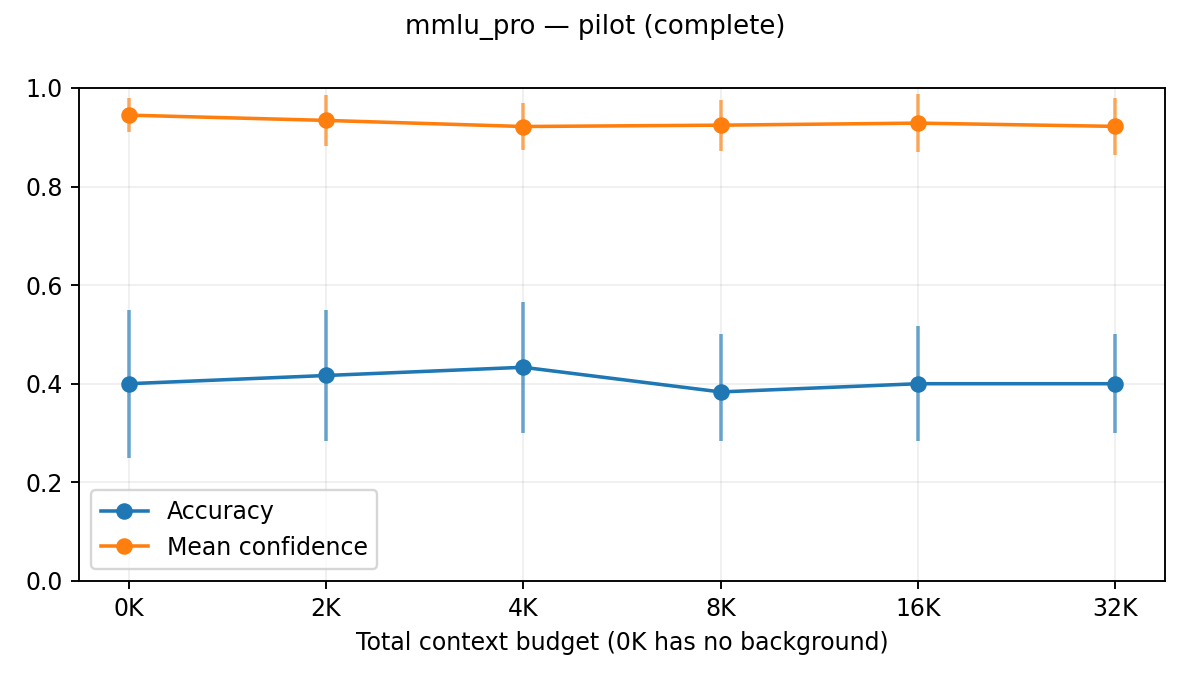

**Calibration metrics**

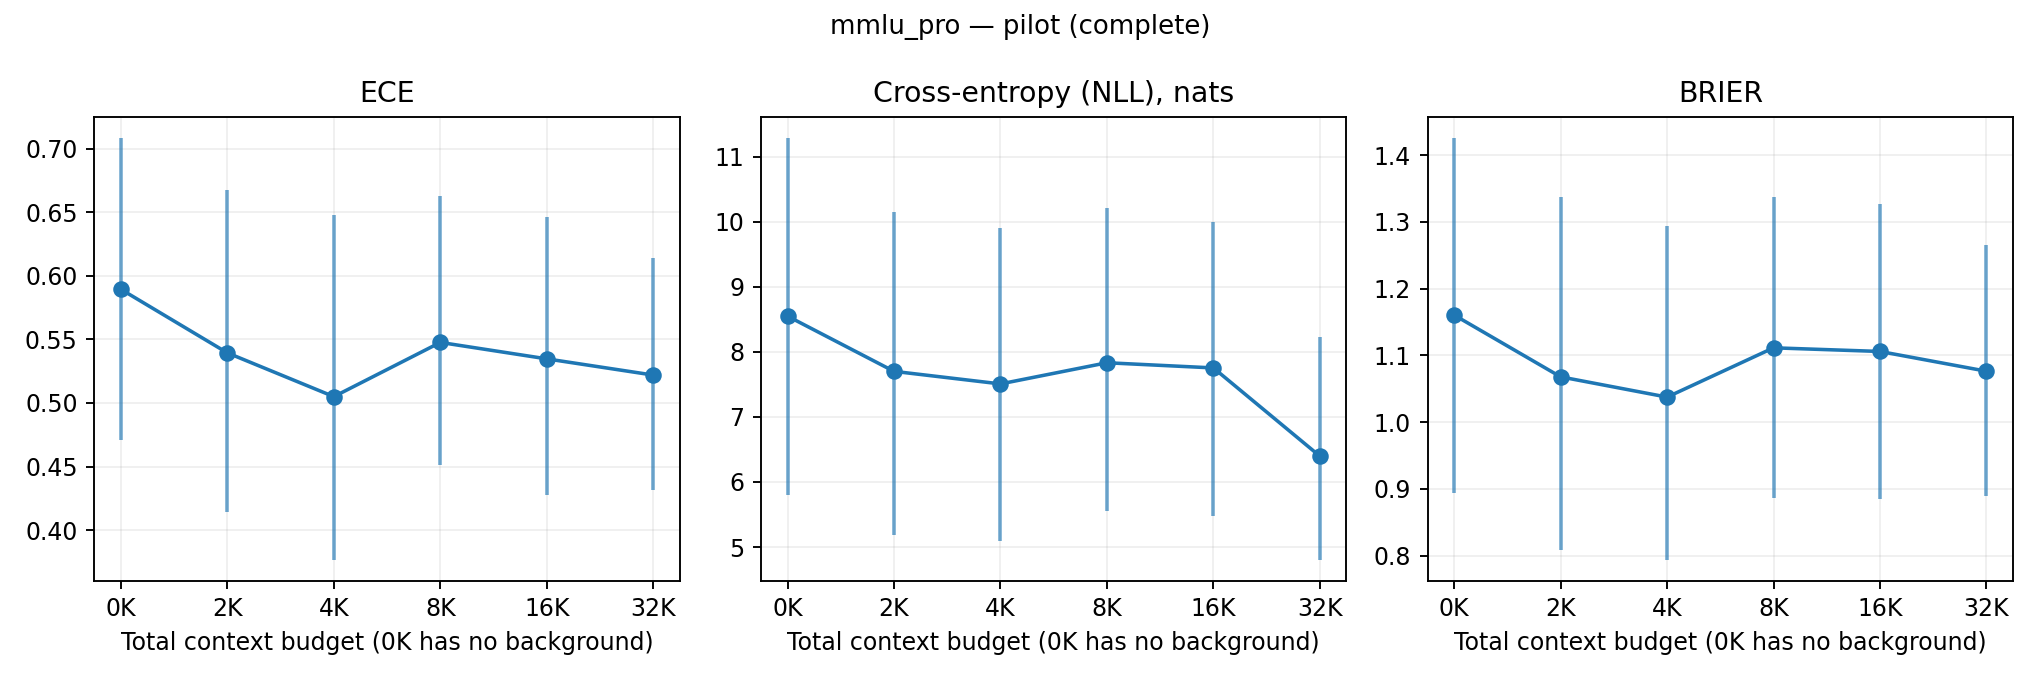

**Reliability diagrams**

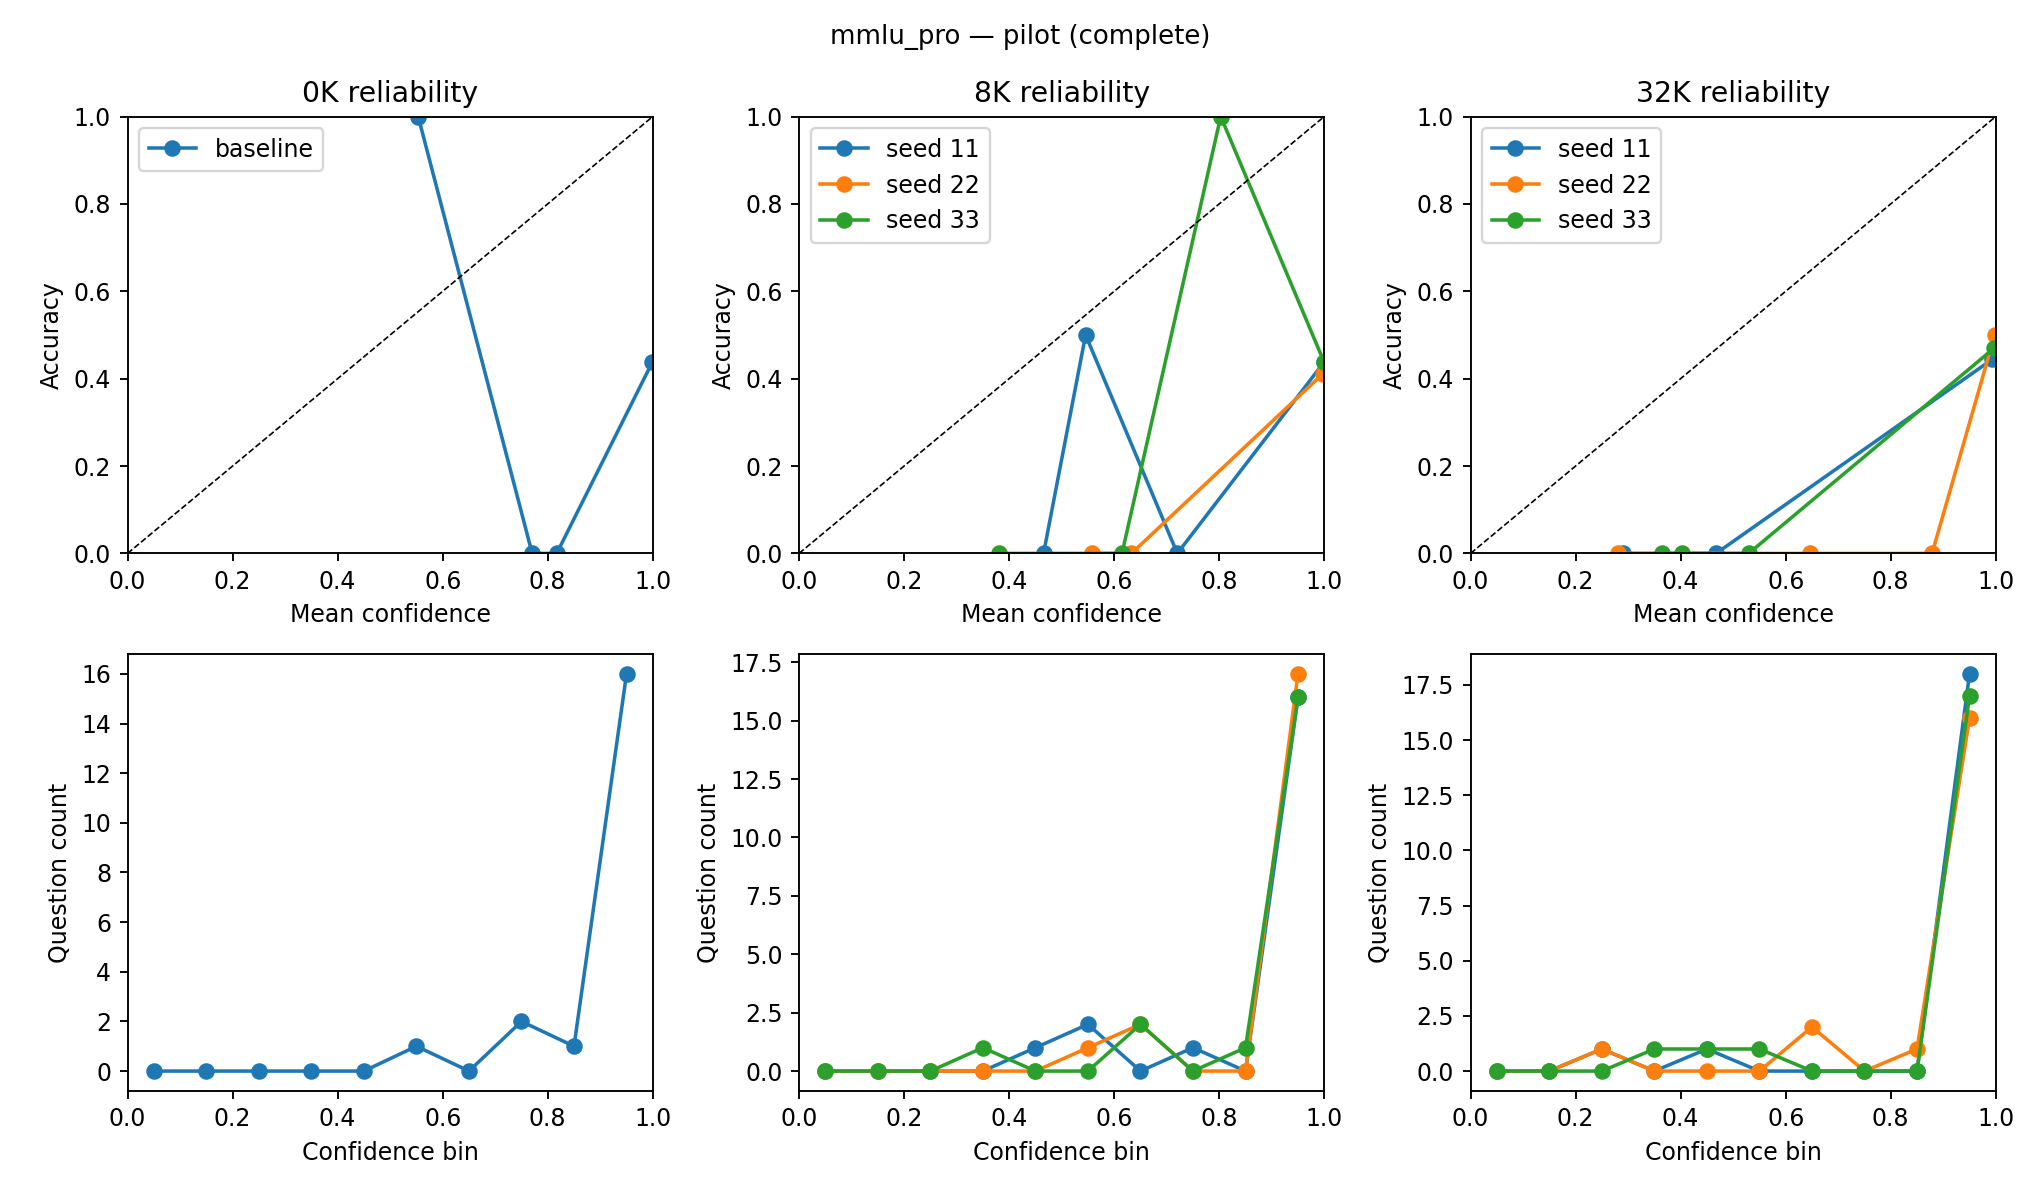

**Paired baseline deltas**

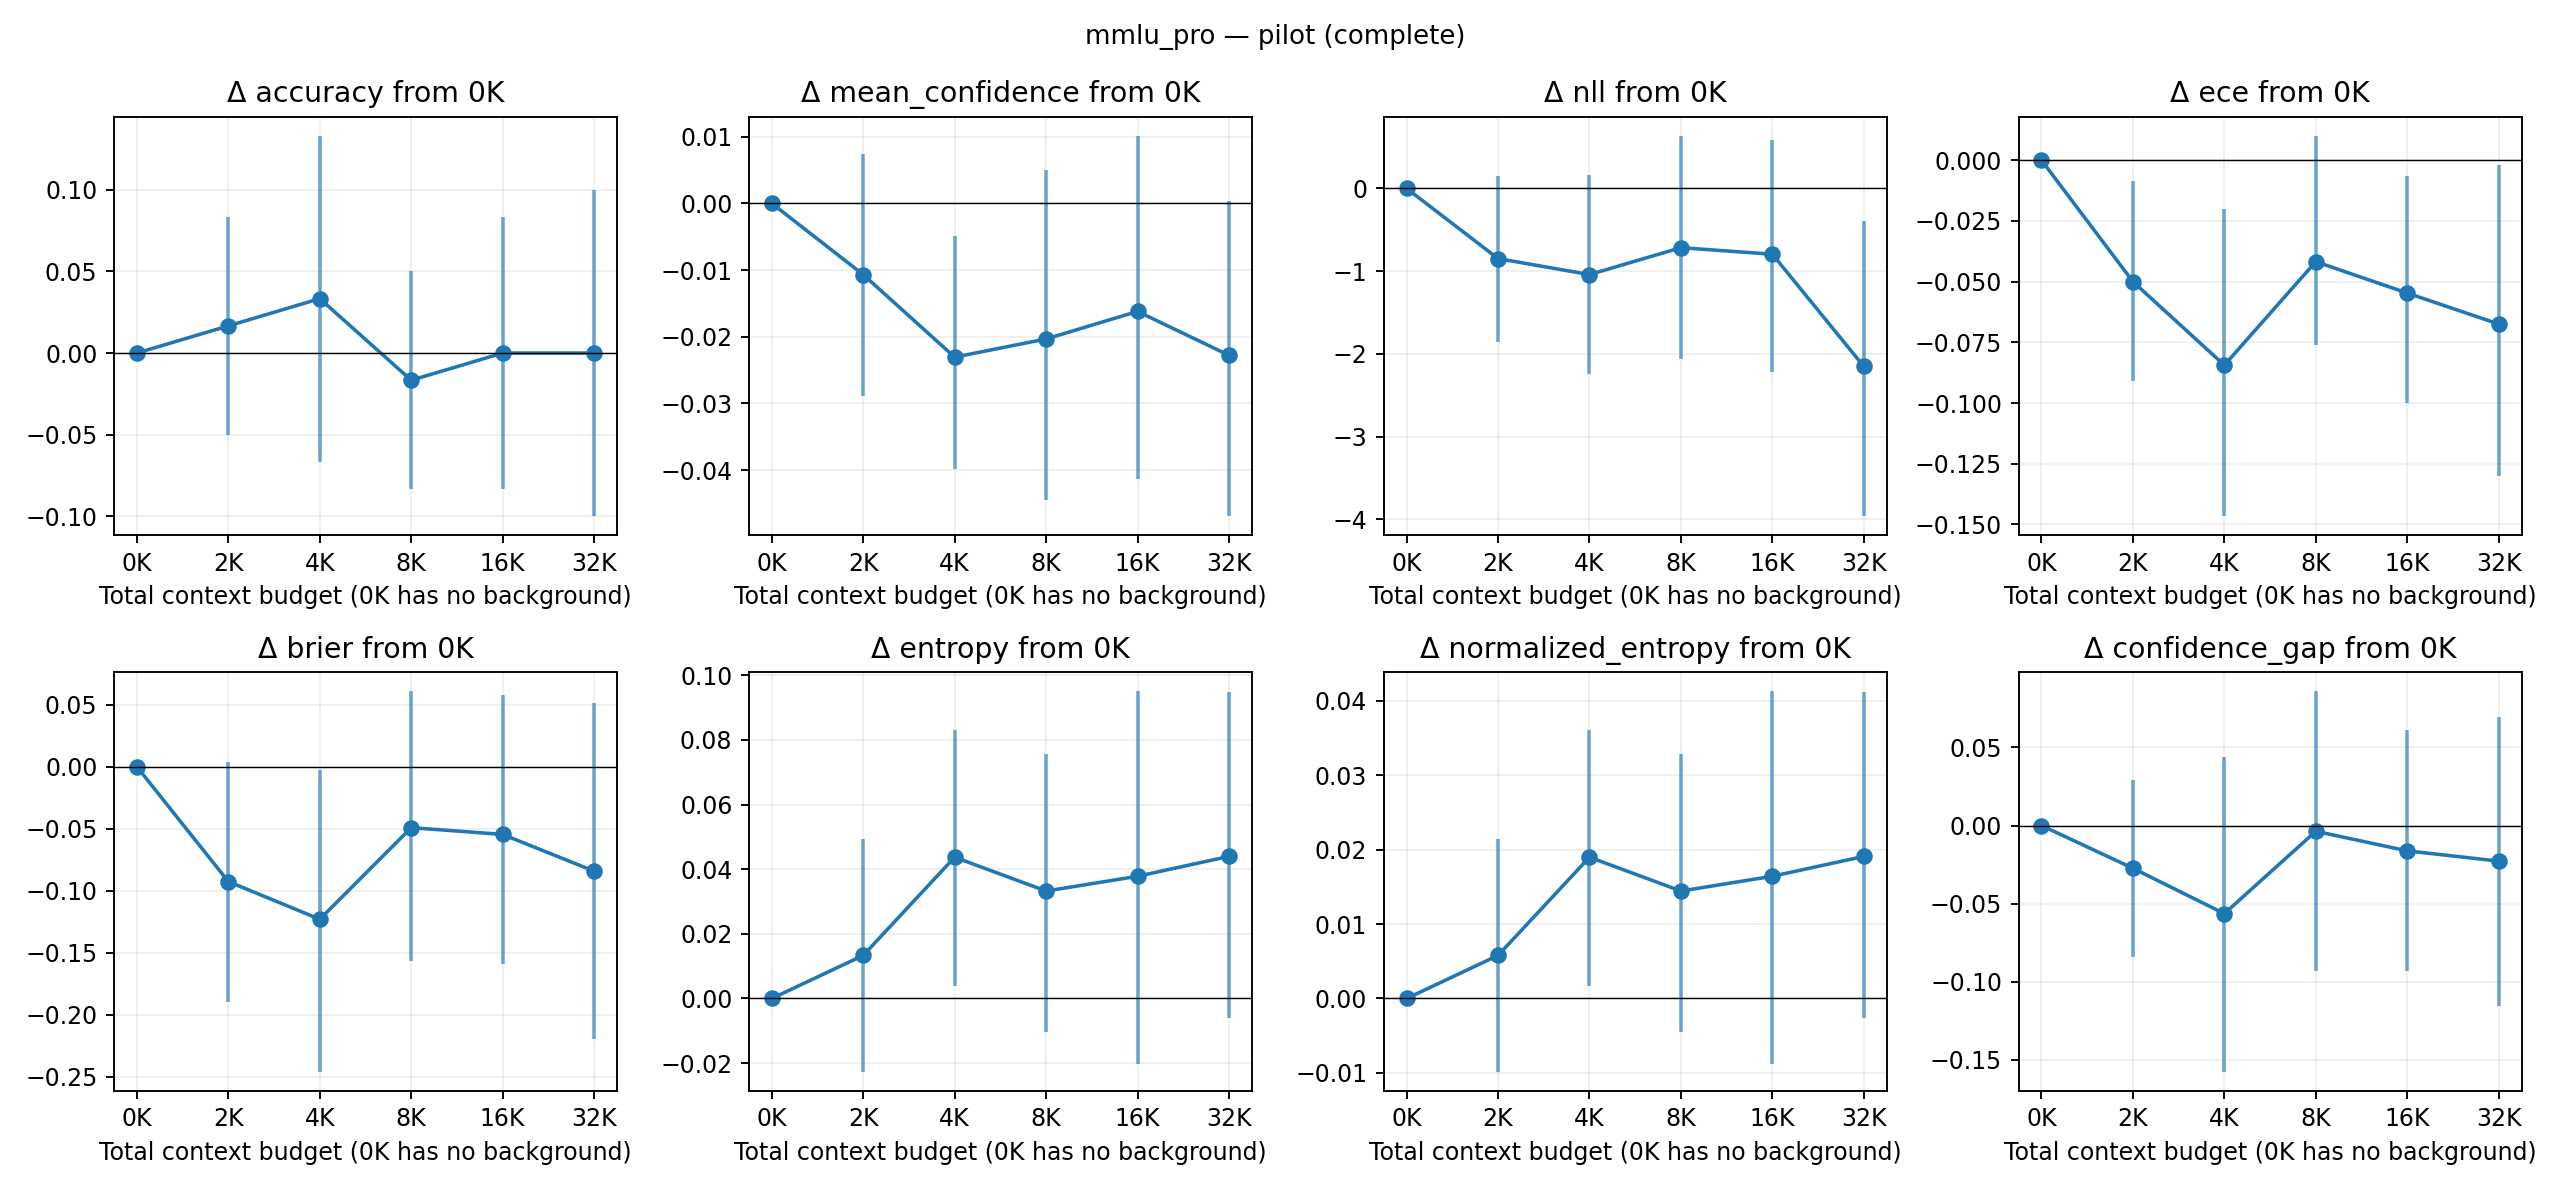

**Timing and memory**

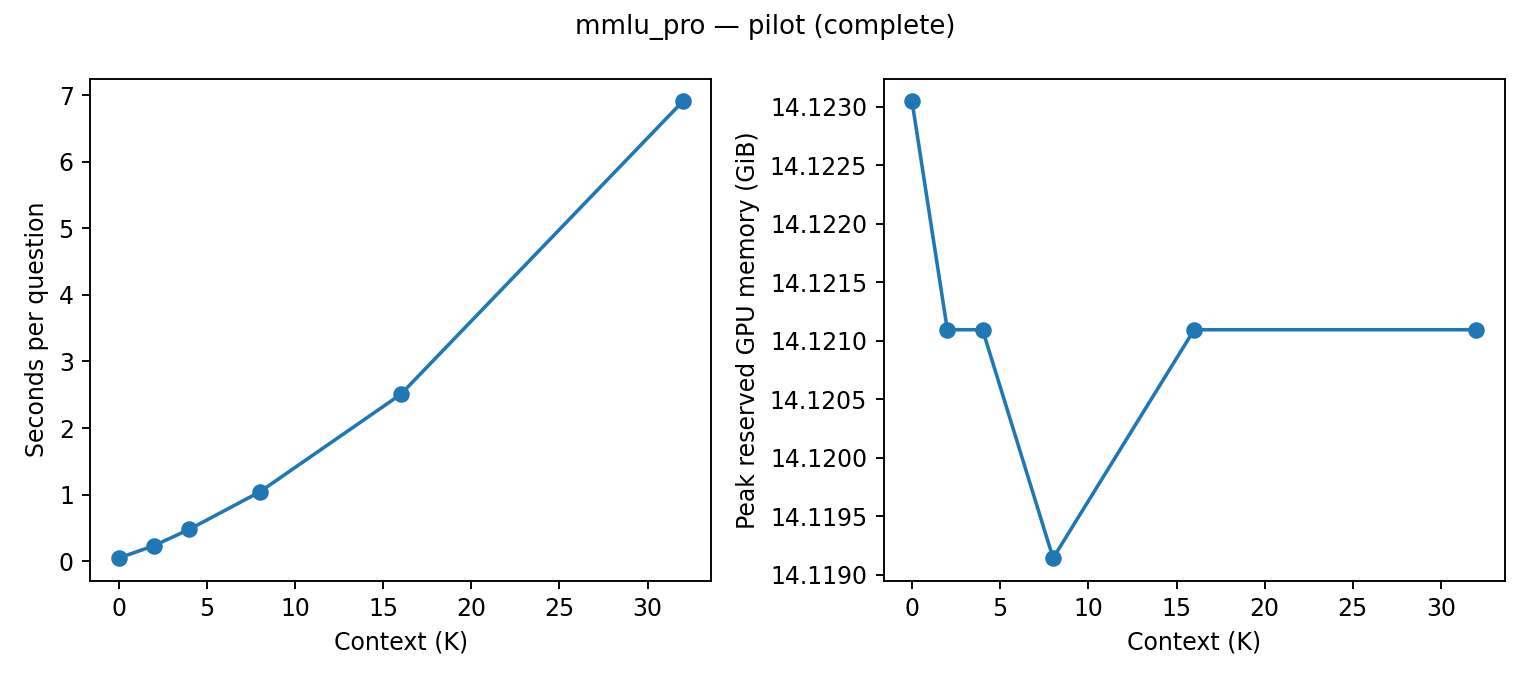

### ARC-Challenge

**Accuracy and confidence**

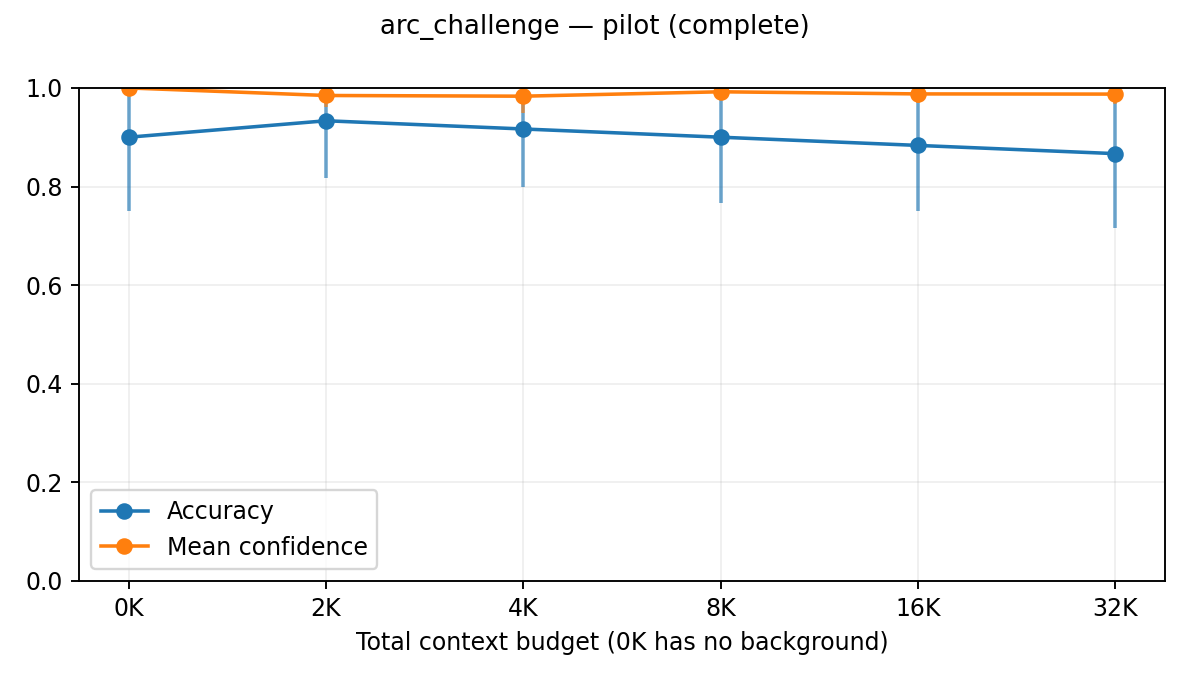

**Calibration metrics**

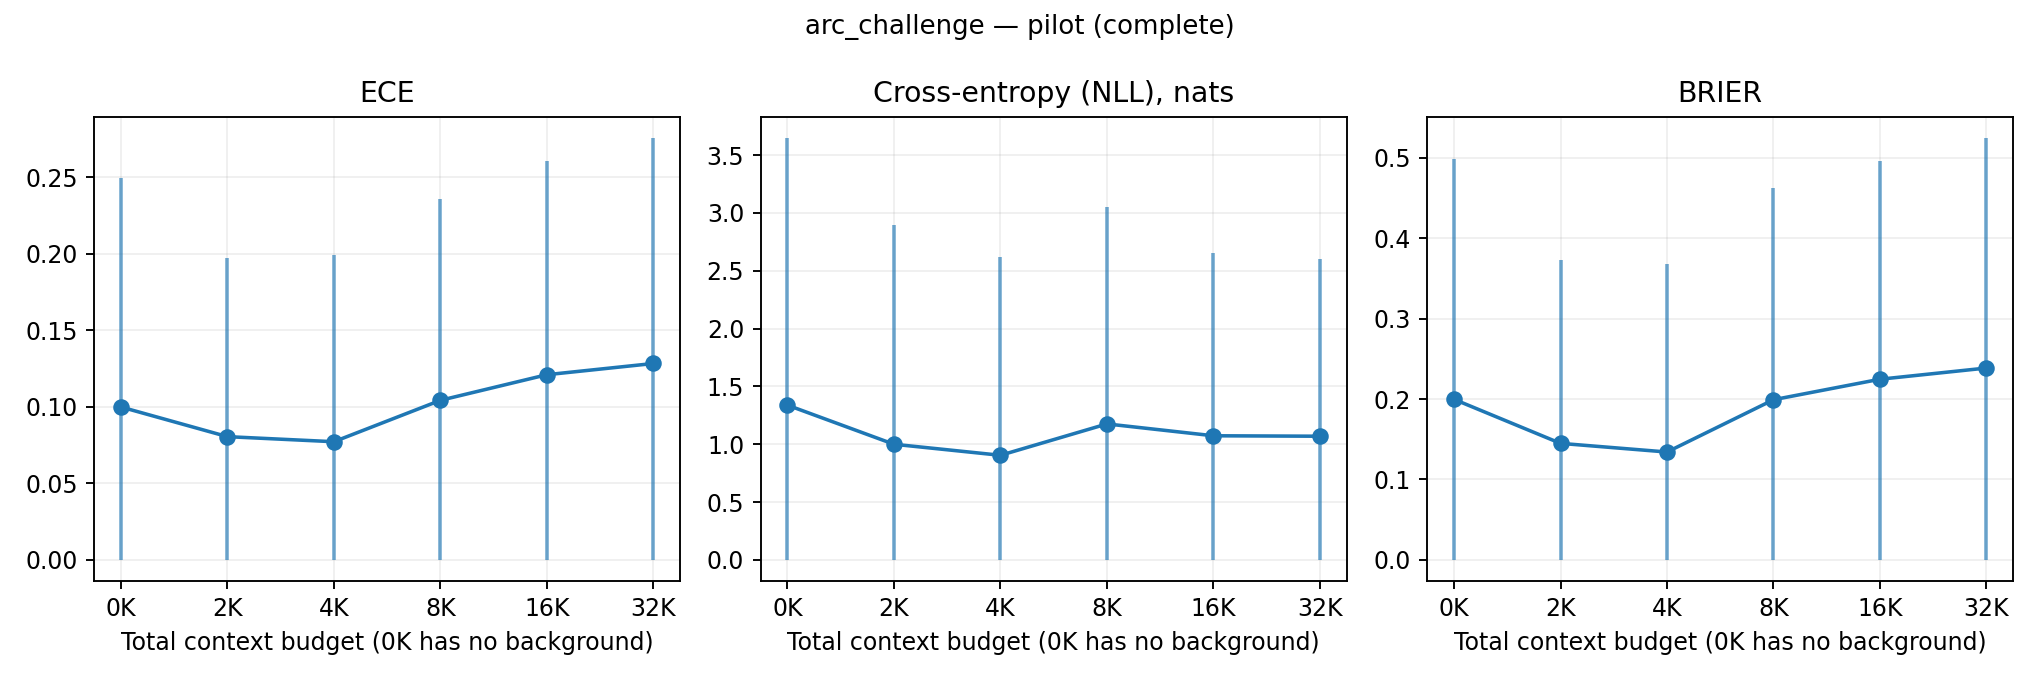

**Reliability diagrams**

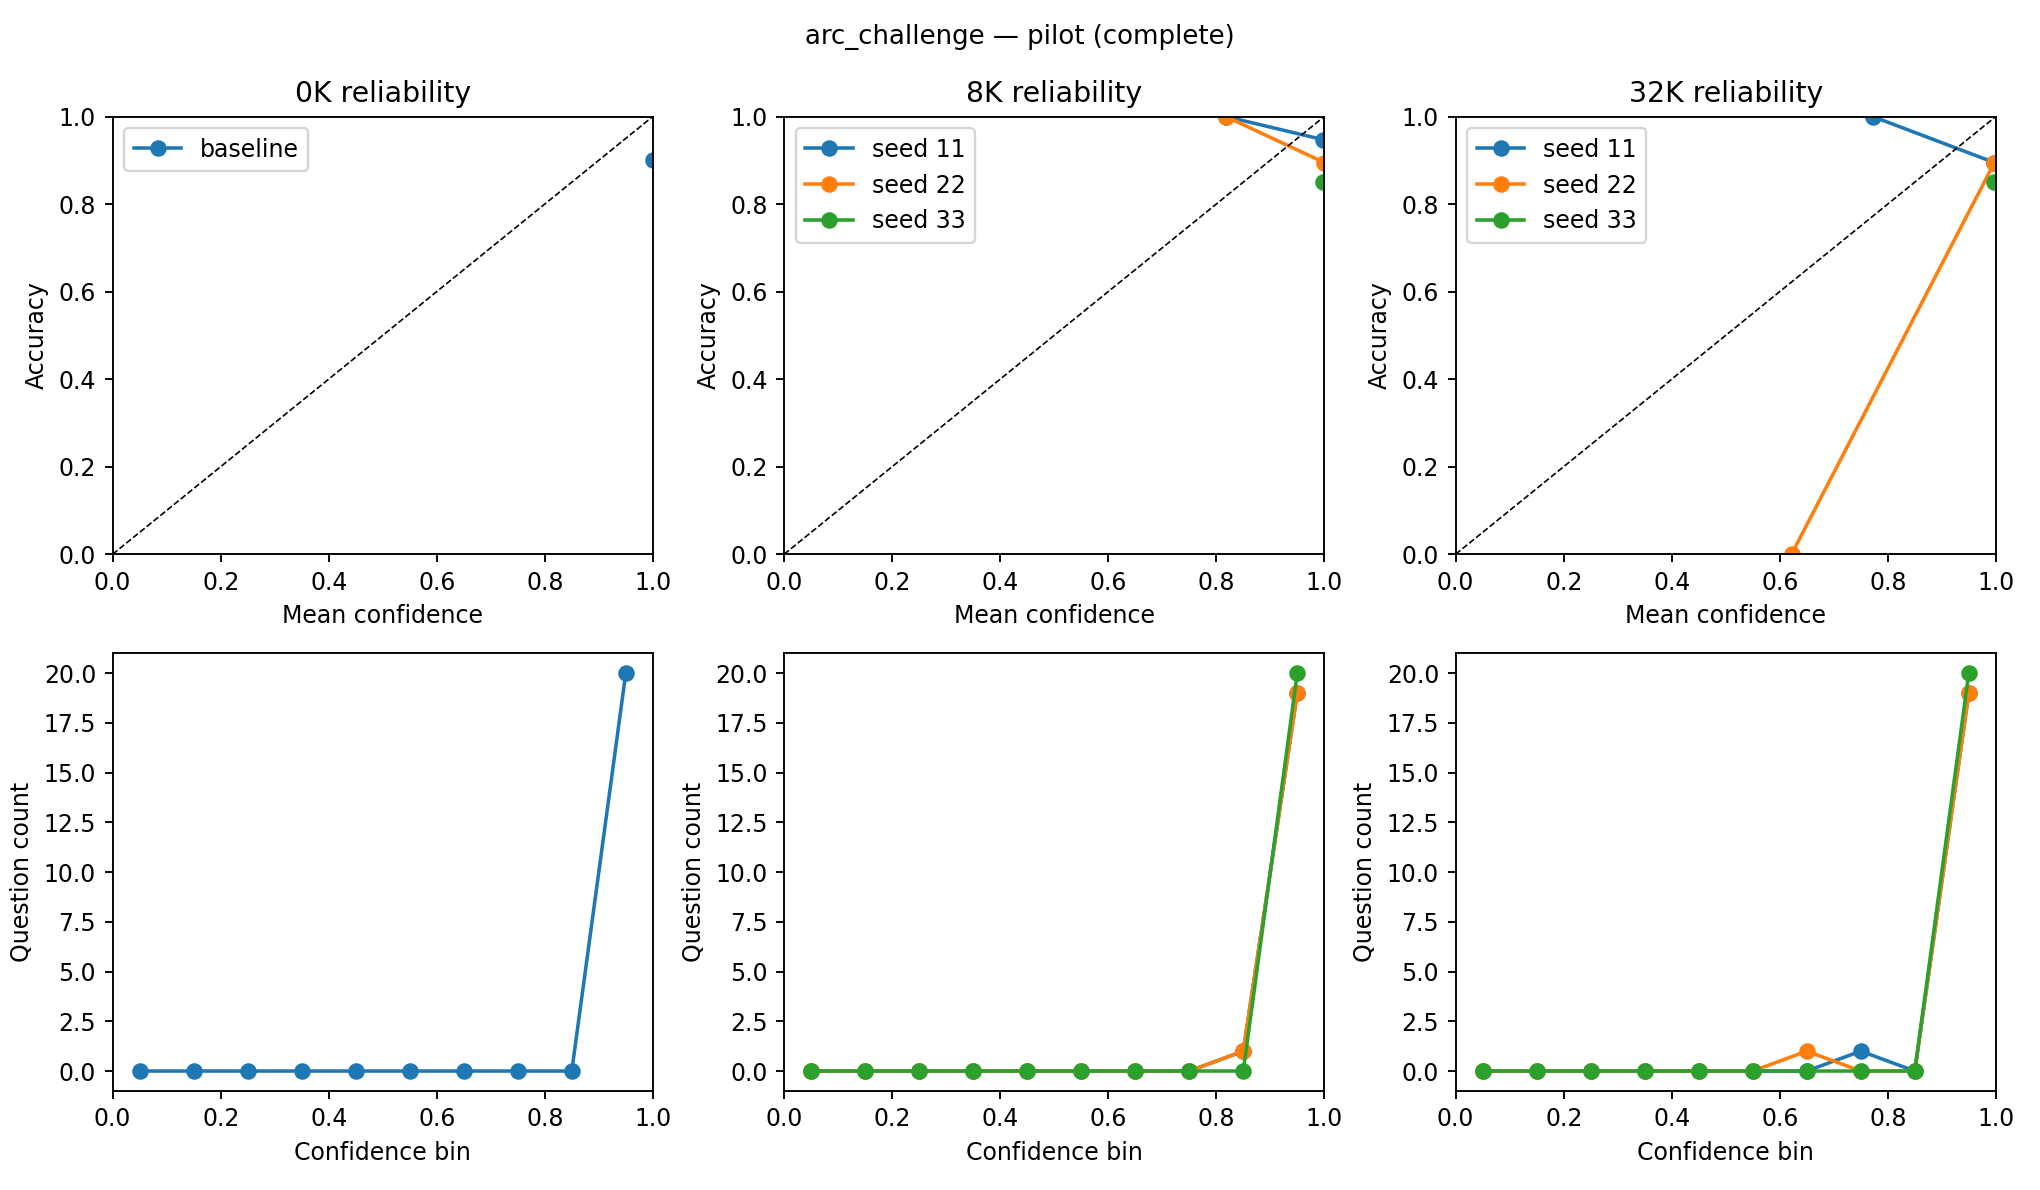

**Paired baseline deltas**

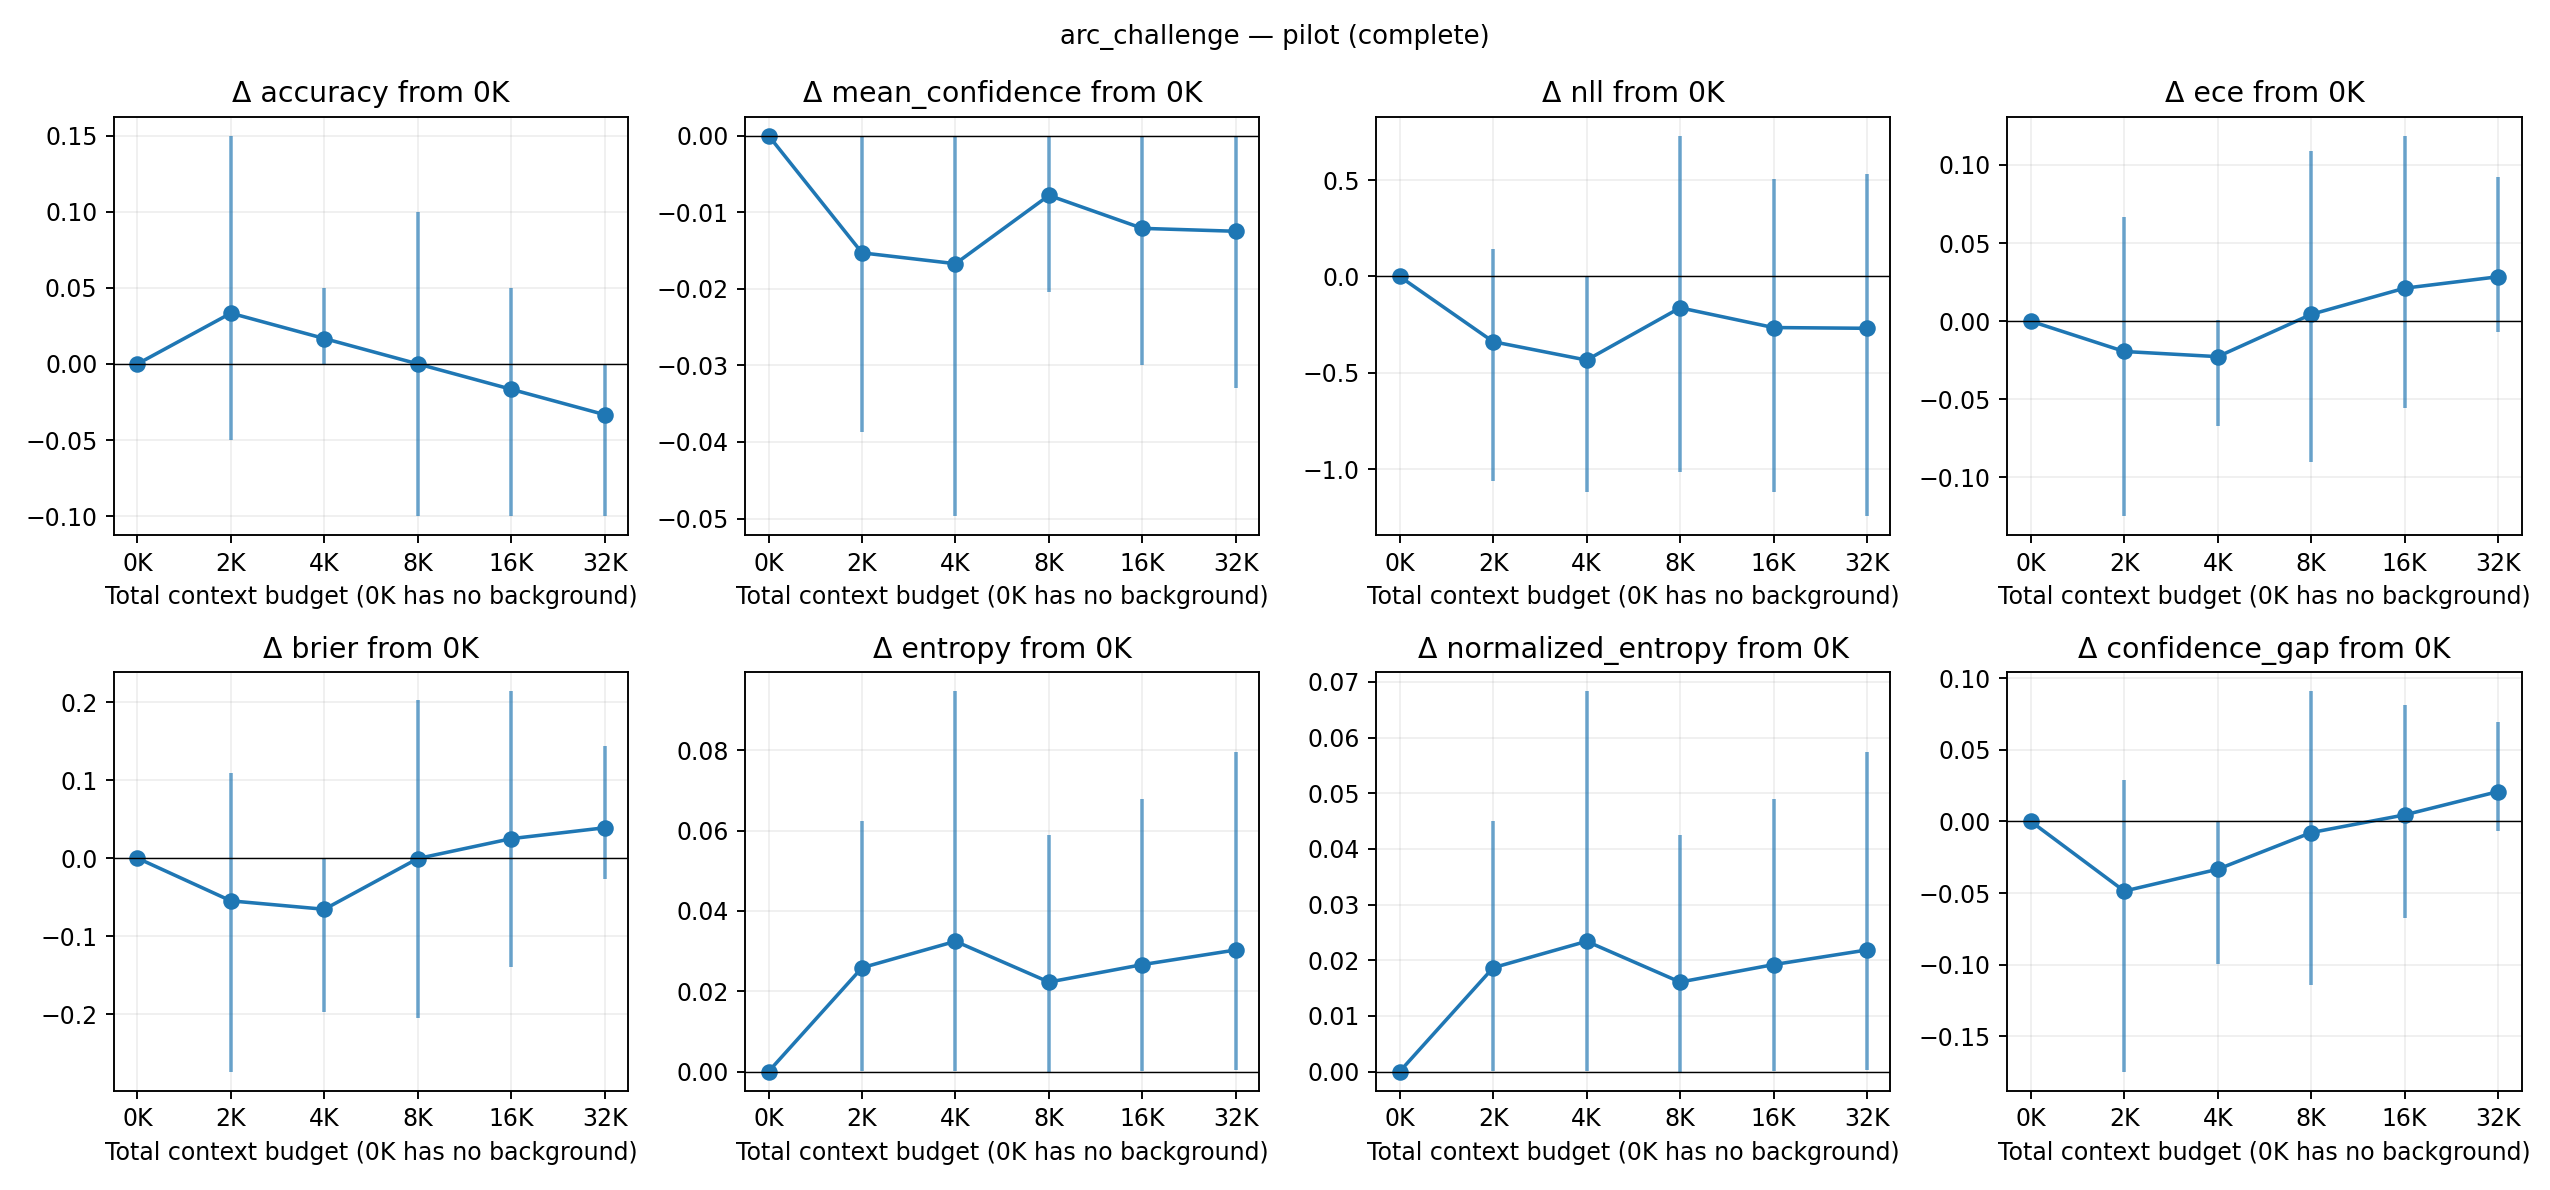

**Timing and memory**

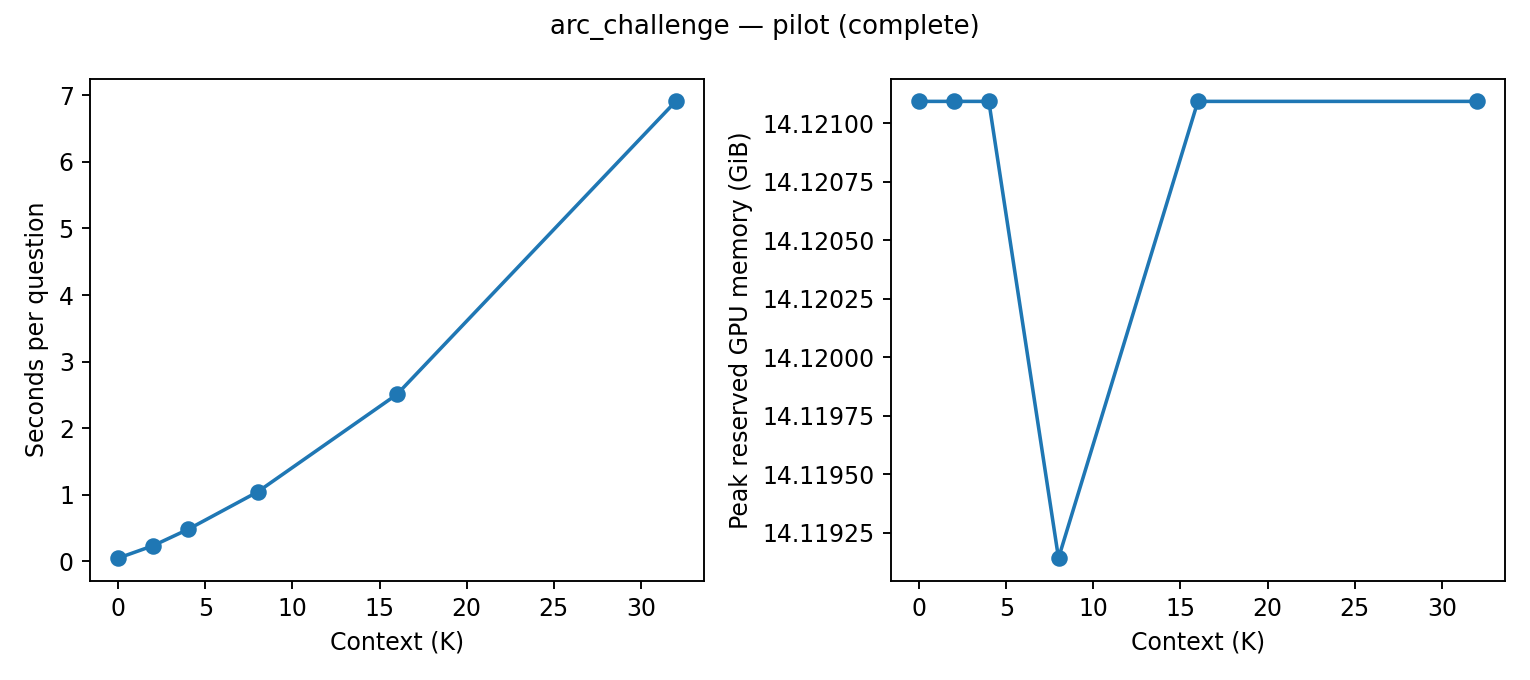